# Quanto risco eu corri para ter esse retorno?

**Python Finance Lab · Aula 2** · *Finanças na prática, notebook por notebook.*

---

## Parte 1 · A pergunta

Na aula 1, vimos onde cada alternativa terminou: **[preencher com o resultado da aula 1]**. Mas o número final esconde o caminho.

Pense em duas carteiras que saem de R\\$ 2.000 e chegam a R\\$ 2.600 em cinco anos. A primeira sobe devagar e quase nunca cai. A segunda chega a valer R\\$ 1.300 no meio do caminho, menos do que você colocou, antes de se recuperar. No fim, o retorno é o mesmo. Mas quantas pessoas teriam aguentado segurar a segunda sem vender no pior momento?

Risco, em investimentos, é isso: a incerteza do caminho. Nesta aula, vamos medi-lo de três formas: quanto a carteira oscila no dia a dia (**volatilidade**), qual foi a maior queda que ela sofreu (**queda máxima**) e quanto retorno ela entregou para cada unidade de risco (**índice de Sharpe**).

Do lado do Python, vamos aprender a escrever **funções**. Cada medida será aplicada a três curvas e a 10 ações, então faz sentido escrever cada conta uma vez só e reutilizá-la.

*Conteúdo exclusivamente educacional. Não constitui recomendação de investimento.*

## Parte 2 · Conceitos

### Bloco 2 · O vocabulário da aula

**Retorno diário.** É a variação percentual do patrimônio de um dia para o outro. É a matéria-prima de quase todas as medidas de risco.

**Volatilidade.** Mede o quanto os retornos diários se espalham em torno da média. Uma aplicação que rende sempre parecido, como o CDI, tem volatilidade quase zero. Uma ação que sobe 3% num dia e cai 4% no outro tem volatilidade alta. A medida estatística usada é o **desvio padrão**. A volatilidade não diz se o investimento vai subir ou cair, e sim o quanto ele balança no caminho.

**Anualização.** Volatilidade e retorno costumam ser expressos por ano, para facilitar a comparação entre investimentos e períodos diferentes. "20% ao ano" é mais fácil de entender do que "1,26% ao dia".

**Queda máxima (drawdown).** O *drawdown* de um dia é o quanto o patrimônio está abaixo do maior valor que já tinha atingido até então. A queda máxima é o pior drawdown do período: a perda de quem comprou exatamente no pico e vendeu exatamente no fundo. É a medida de risco mais fácil de sentir na pele.

**Índice de Sharpe.** Mede quanto retorno acima da renda fixa o investimento entregou para cada unidade de volatilidade. Se duas carteiras renderam o mesmo, a de maior Sharpe chegou lá balançando menos. Um Sharpe negativo significa que o investimento rendeu menos que o CDI: correu risco e, mesmo assim, perdeu para a alternativa sem risco de oscilação.

**Taxa livre de risco.** É o rendimento de uma aplicação sem risco de oscilação, usado como régua pelo Sharpe. No Brasil, a referência natural é o CDI.

## Parte 3 · Fórmulas

### Bloco 3 · As contas da aula

**Retorno diário.** Se $V_t$ é o valor no dia $t$:

$$r_t = \frac{V_t}{V_{t-1}} - 1$$

*Exemplo:* de 100 para 102, $r = 102/100 - 1 = 2\%$.

**Volatilidade diária.** É o desvio padrão dos retornos diários, a distância típica entre o retorno de um dia e o retorno médio $\bar{r}$:

$$\sigma = \sqrt{\frac{1}{n-1}\sum_{t=1}^{n}\left(r_t - \bar{r}\right)^2}$$

**Volatilidade anual.**

$$\sigma_{\text{anual}} = \sigma_{\text{diária}} \times \sqrt{252}$$

Por que a raiz de 252? Um ano tem cerca de 252 dias úteis. Se os retornos de cada dia são independentes entre si, as variâncias (o quadrado do desvio padrão) se somam: a variância de um ano é 252 vezes a de um dia. Para voltar ao desvio padrão, tiramos a raiz quadrada, e o fator vira $\sqrt{252} \approx 15{,}9$. *Exemplo:* 1% ao dia equivale a cerca de 15,9% ao ano.

**Retorno anual.** Se o retorno no período inteiro foi $R$:

$$R_{\text{anual}} = (1 + R)^{1/\text{anos}} - 1, \qquad \text{anos} = \frac{\text{dias corridos}}{365{,}25}$$

*Exemplo:* 21% em 2 anos dão $1{,}21^{1/2} - 1 = 10\%$ ao ano, porque $1{,}10 \times 1{,}10 = 1{,}21$. Não são 10,5% (21 dividido por 2), por causa dos juros compostos.

**Drawdown e queda máxima.**

$$DD_t = \frac{V_t}{\max_{s \le t} V_s} - 1 \qquad\qquad \text{Queda máxima} = \min_t DD_t$$

*Exemplo:* na sequência 100 → 120 → 90 → 110, o pico é 120 e o fundo é 90. A queda máxima é $90/120 - 1 = -25\%$. A queda é medida a partir do pico, e não do valor inicial.

**Índice de Sharpe.**

$$\text{Sharpe} = \frac{R_{\text{anual}} - R^{\text{CDI}}_{\text{anual}}}{\sigma_{\text{anual}}}$$

*Exemplo:* uma carteira que rendeu 12% ao ano, com CDI de 10% ao ano e volatilidade de 20% ao ano, tem Sharpe de $(12 - 10)/20 = 0{,}10$.

## Parte 4 · Implementação

### Bloco 4 · Importar as bibliotecas

As mesmas bibliotecas da aula 1. Se estiver usando um computador novo, rode antes `%pip install yfinance pandas matplotlib requests`.

> **O que esperar:** nada, se tudo estiver instalado. Se aparecer `ModuleNotFoundError`, instale com o `%pip` acima e reinicie o kernel (menu Kernel → Restart Kernel).

In [1]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
import requests

### Bloco 5 · As premissas

As mesmas premissas da aula 1. A lista de ações está escrita em duas linhas, sem os comentários, só para ocupar menos espaço: o conteúdo é idêntico.

> **O que esperar:** nada.

In [2]:
ACOES = [
    "ITUB4.SA", "VALE3.SA", "PETR4.SA", "WEGE3.SA", "ABEV3.SA",
    "EGIE3.SA", "SUZB3.SA", "RADL3.SA", "VIVT3.SA", "TOTS3.SA",
]
INDICE = "^BVSP"
DATA_INICIO = "2021-10-01"
DATA_FIM = "2026-09-30"
CAPITAL = 2000

### Bloco 6 · Os dados da aula 1

Este bloco repete os blocos 7 a 12 da aula 1, sem as inspeções intermediárias: ações e Ibovespa do Yahoo Finance e CDI do Banco Central.

Repare no `.ffill()` logo depois do `.loc`, na mesma linha. O pandas permite **encadear** operações: cada uma é aplicada ao resultado da anterior.

Repare também em quanto código precisamos repetir para voltar ao ponto de partida. Na aula 10, vamos guardar esse trecho num arquivo próprio e chamá-lo com uma linha.

> **O que esperar:** nada. Os dados ficam guardados nas variáveis `precos`, `ibov` e `cdi_diario`.

In [3]:
# Ações e Ibovespa (Yahoo Finance), como na aula 1
dados = yf.download(ACOES, start=DATA_INICIO, auto_adjust=True, progress=False)
precos = dados["Close"].loc[DATA_INICIO:DATA_FIM].ffill()
precos.columns = precos.columns.str.replace(".SA", "")

dados_ibov = yf.download(
    INDICE, start=DATA_INICIO, auto_adjust=True, progress=False, multi_level_index=False
)
ibov = dados_ibov["Close"].loc[DATA_INICIO:DATA_FIM]

# CDI (Banco Central), como na aula 1
inicio_bc = pd.to_datetime(DATA_INICIO).strftime("%d/%m/%Y")
fim_bc = pd.to_datetime(DATA_FIM).strftime("%d/%m/%Y")
url = (
    "https://api.bcb.gov.br/dados/serie/bcdata.sgs.12/dados"
    f"?formato=json&dataInicial={inicio_bc}&dataFinal={fim_bc}"
)
resposta = requests.get(url, timeout=60)
resposta.raise_for_status()
cdi_bruto = pd.DataFrame(resposta.json())
cdi_bruto["data"] = pd.to_datetime(cdi_bruto["data"], format="%d/%m/%Y")
cdi_bruto["valor"] = cdi_bruto["valor"].astype(float)
cdi_diario = cdi_bruto.set_index("data")["valor"]

### Bloco 7 · As três curvas da aula 1

Também da aula 1: carteira, Ibovespa e CDI em reais, começando em R\\$ 2.000. A conta da carteira cabe agora numa linha só: `(precos / precos.iloc[0]).mean(axis=1) * CAPITAL` faz em sequência o que os blocos 13 e 14 da aula 1 faziam em duas etapas. Os parênteses garantem que a divisão aconteça antes da média.

> **O que esperar:** as cinco últimas linhas das três curvas, com os mesmos valores da tabela final da aula 1.

In [4]:
# As três curvas em reais, como na aula 1
carteira = (precos / precos.iloc[0]).mean(axis=1) * CAPITAL
ibov_reais = ibov / ibov.iloc[0] * CAPITAL
cdi_acumulado = (1 + cdi_diario / 100).cumprod()
cdi_reais = cdi_acumulado / cdi_acumulado.iloc[0] * CAPITAL

curvas = pd.concat([carteira, ibov_reais, cdi_reais], axis=1, join="inner")
curvas.columns = ["Carteira", "Ibovespa", "CDI"]
curvas.tail()

,Carteira,Ibovespa,CDI
2026-09-24,3718.463807,3258.919398,3616.959620
2026-09-25,3684.806045,3250.256864,3618.796601
2026-09-28,3670.750269,3241.647476,3620.634516
2026-09-29,3693.029669,3256.474756,3622.473363
2026-09-30,3712.681113,3300.974314,3624.313145


### Bloco 8 · Os retornos diários

Todas as medidas de risco partem dos retornos diários. O `pct_change()` calcula a variação percentual de cada linha em relação à anterior, exatamente a fórmula $r_t = V_t / V_{t-1} - 1$, nas três colunas de uma vez.

O primeiro dia não tem dia anterior, então o resultado dele fica vazio. O `dropna()` remove essa linha.

Multiplicamos por 100 só na exibição, para ler os números em %.

> **O que esperar:** os retornos dos cinco primeiros dias, em %. A coluna do CDI mostra números pequenos e quase iguais todos os dias; as outras duas alternam altas e baixas.

In [5]:
retornos = curvas.pct_change().dropna()
(retornos * 100).head()

,Carteira,Ibovespa,CDI
2021-10-04,-3.431916,-2.220549,0.023687
2021-10-05,-0.319921,0.058881,0.023687
2021-10-06,-0.160173,0.092343,0.023687
2021-10-07,0.341580,0.022612,0.023687
2021-10-08,1.735093,2.032825,0.023687


### Bloco 9 · O que a volatilidade mede

Um histograma mostra quantos dias tiveram retornos em cada faixa de valores. Ele deixa visível o que a volatilidade mede: a largura do "sino".

- `r` guarda os retornos diários da carteira, em %.
- `r.std()` calcula o desvio padrão.
- `plot.hist(bins=60)` divide os retornos em 60 faixas e conta os dias de cada uma.
- As duas linhas tracejadas marcam um desvio padrão acima e abaixo de zero.

A última conta usa um truque útil. `r.abs() <= desvio` cria uma série de verdadeiro ou falso, com um valor para cada dia: verdadeiro se o retorno daquele dia ficou dentro da faixa. Para o Python, verdadeiro vale 1 e falso vale 0. Então, a média dessa série é a proporção de dias dentro da faixa.

> **O que esperar:** um histograma em forma de sino, com a maioria dos dias perto de zero e poucos dias extremos nas pontas. O `:.2f` dentro da f-string formata o número com duas casas decimais. Se os retornos seguissem exatamente a curva normal da estatística, cerca de 68% dos dias ficariam dentro da faixa. Com ações, costuma dar um pouco mais, porque há mais dias calmos e mais dias extremos do que a curva normal prevê.

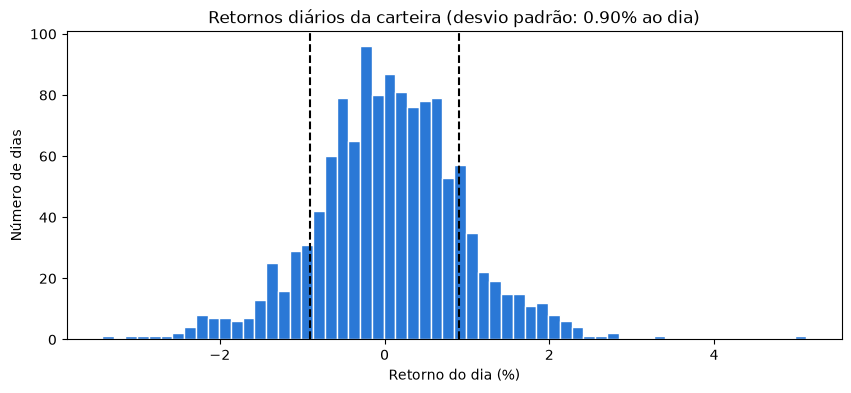

Dias dentro da faixa de ±1 desvio: 72%


In [6]:
r = retornos["Carteira"] * 100
desvio = r.std()

ax = r.plot.hist(bins=60, figsize=(10, 4), color="#2a78d6", edgecolor="white")
ax.axvline(desvio, color="black", linestyle="--", linewidth=1.5)
ax.axvline(-desvio, color="black", linestyle="--", linewidth=1.5)
ax.set_title(f"Retornos diários da carteira (desvio padrão: {desvio:.2f}% ao dia)")
ax.set_xlabel("Retorno do dia (%)")
ax.set_ylabel("Número de dias")
plt.show()

dentro = (r.abs() <= desvio).mean() * 100
print(f"Dias dentro da faixa de ±1 desvio: {dentro:.0f}%")

**O que o histograma mostra.** **[Preencher: o desvio padrão diário e a proporção de dias dentro da faixa.]**

### Bloco 10 · A primeira função: retorno total

Uma função é um bloco de código com nome, que recebe valores, faz uma conta e devolve um resultado. Você já usou várias: `print`, `len`, `yf.download`. Agora vamos escrever a nossa. A anatomia de uma função:

- **`def`** avisa ao Python que vem a definição de uma função.
- **`retorno_total`** é o nome. Escolha nomes que digam o que a função faz.
- **`serie`**, entre parênteses, é o **parâmetro**: o nome que o valor recebido terá dentro da função.
- O texto entre três aspas é a **docstring**, a descrição da função. Ela aparece quando alguém pede ajuda sobre a função, por exemplo com `help(retorno_total)`.
- **`return`** devolve o resultado para quem chamou a função.
- Tudo o que pertence à função fica **recuado**, com 4 espaços. É assim que o Python sabe onde a função termina.

Escrever a função não executa a conta, só a ensina ao Python. Para saber se ela funciona, testamos com um exemplo de resposta conhecida: uma série que vai de 100 a 121 teve retorno de 21%.

Arredondamos o resultado do teste com `round(..., 4)` porque o computador guarda números decimais com pequenas imprecisões, e o resultado poderia aparecer como `0.20999999999999996`.

> **O que esperar:** `0.21`. O `pd.Series([100, 110, 121])` cria uma série de teste a partir de uma lista.

In [7]:
def retorno_total(serie):
    """Retorno do período inteiro: quanto R$ 1 virou, menos o R$ 1."""
    return serie.iloc[-1] / serie.iloc[0] - 1


print(round(retorno_total(pd.Series([100, 110, 121])), 4))   # esperado: 0.21

0.21


### Bloco 11 · Uma função, três curvas

Agora, a mesma função aplicada às três curvas. O `apply` chama a função uma vez para cada coluna da tabela, passando a coluna como o parâmetro `serie`, e junta os resultados.

É por isso que vale a pena escrever funções: a conta foi escrita uma vez e roda em quantas séries quisermos. Multiplicamos por 100 para ler em %.

> **O que esperar:** o retorno no período de cada curva, em %. Os números devem bater com a tabela final da aula 1.

In [8]:
curvas.apply(retorno_total) * 100

Carteira    85.634056
Ibovespa    65.048716
CDI         81.215657
dtype: float64

### Bloco 12 · Retorno por ano

O retorno total depende do tamanho do período: 30% em dois anos é muito melhor que 30% em dez. Para comparar, convertemos tudo em retorno por ano.

Esta função chama outra: usa `retorno_total` dentro dela. Funções podem ser combinadas como peças de montar.

- `serie.index[-1] - serie.index[0]` é a distância entre a última e a primeira data, e o `.days` a converte em número de dias.
- Dividindo por 365,25, a duração média de um ano contando os bissextos, temos o número de anos.
- `** (1 / anos)` eleva à potência 1/anos, a operação inversa dos juros compostos. O `**` é o operador de potência do Python.

> **O que esperar:** `Anos no período: 5.0` e o retorno anual de cada curva, em %.

In [9]:
def retorno_anual(serie):
    """Retorno médio por ano, com juros compostos (anos contados em dias corridos)."""
    anos = (serie.index[-1] - serie.index[0]).days / 365.25
    return (1 + retorno_total(serie)) ** (1 / anos) - 1


print("Anos no período:", round((curvas.index[-1] - curvas.index[0]).days / 365.25, 2))
curvas.apply(retorno_anual) * 100

Anos no período: 5.0


Carteira    13.179646
Ibovespa    10.548344
CDI         12.635298
dtype: float64

### Bloco 13 · Volatilidade por ano

A volatilidade usa os retornos diários, por isso a função começa calculando-os com `pct_change`, como no bloco 8. Depois, `std()` calcula o desvio padrão, e `252 ** 0.5` é a raiz quadrada de 252: elevar a 0,5 é o mesmo que tirar a raiz quadrada.

A variável `retornos_diarios` só existe dentro da função: é criada quando a função roda e desaparece quando ela termina. Por isso, seu nome não entra em conflito com as variáveis do resto do notebook.

> **O que esperar:** a volatilidade anual de cada curva, em %. A do CDI fica bem abaixo de 1% ao ano: ele sobe todo dia, quase sempre na mesma medida, e só muda de ritmo quando a Selic muda. As volatilidades da carteira e do Ibovespa são muito maiores.

In [10]:
def volatilidade_anual(serie):
    """Desvio padrão dos retornos diários, levado para a escala de um ano."""
    retornos_diarios = serie.pct_change().dropna()
    return retornos_diarios.std() * 252 ** 0.5


curvas.apply(volatilidade_anual) * 100

Carteira    14.281901
Ibovespa    17.393720
CDI          0.124116
dtype: float64

**O que as volatilidades mostram.** **[Preencher: a volatilidade anual da carteira, do Ibovespa e do CDI.]**

### Bloco 14 · Drawdown e queda máxima

Duas funções, uma usando a outra.

- **`drawdown`** devolve uma série inteira: para cada dia, o quanto o valor está abaixo do maior valor atingido até ali. O `cummax()` é o **máximo acumulado**: em cada linha, o maior valor visto até aquele dia, o "recorde" da série.
- **`queda_maxima`** pega o pior momento dessa série com `min()`.

O teste usa o exemplo do bloco 3: na sequência 100, 120, 90, 110, a queda máxima é de 25%.

> **O que esperar:** `-0.25` no teste e a queda máxima de cada curva, em %. A do CDI é zero, porque ele nunca caiu.

In [11]:
def drawdown(serie):
    """Para cada dia: quanto a série está abaixo do maior valor já atingido até ali."""
    pico = serie.cummax()
    return serie / pico - 1


def queda_maxima(serie):
    """A pior queda do período, do pico ao fundo."""
    return drawdown(serie).min()


print(round(queda_maxima(pd.Series([100, 120, 90, 110])), 4))   # esperado: -0.25
curvas.apply(queda_maxima) * 100

-0.25


Carteira   -16.134666
Ibovespa   -20.933618
CDI          0.000000
dtype: float64

**O que as quedas mostram.** **[Preencher: a queda máxima da carteira e a do Ibovespa.]**

### Bloco 15 · O gráfico das quedas

O drawdown dia a dia mostra quanto tempo cada curva passou abaixo do próprio recorde e quão fundo ela foi.

Desta vez, o `apply` devolve uma tabela, e não um número por coluna, porque a função `drawdown` devolve uma série inteira para cada coluna. Deixamos o CDI de fora: a linha dele ficaria grudada no zero.

O gráfico se lê assim: zero significa que a curva está no recorde; −20 significa que está 20% abaixo do melhor momento até então.

> **O que esperar:** duas linhas que encostam no zero quando a curva bate um novo recorde e afundam nos períodos de queda.

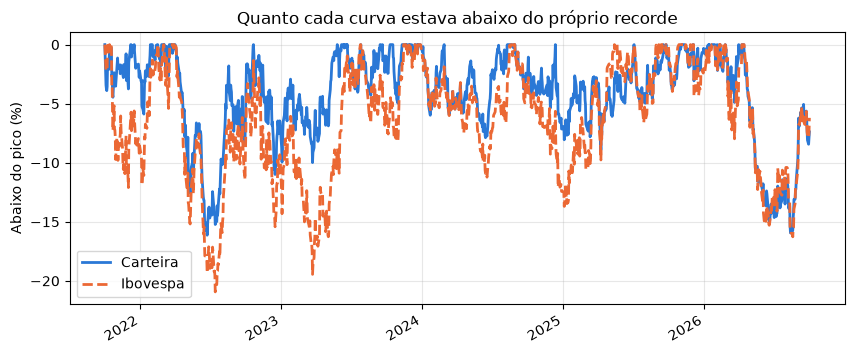

In [12]:
quedas = curvas[["Carteira", "Ibovespa"]].apply(drawdown) * 100

ax = quedas.plot(
    figsize=(10, 4),
    style=["-", "--"],
    color=["#2a78d6", "#eb6834"],
    linewidth=2,
    title="Quanto cada curva estava abaixo do próprio recorde",
)
ax.set_ylabel("Abaixo do pico (%)")
ax.set_xlabel("")
ax.grid(alpha=0.3)
plt.show()

**O que o gráfico mostra.** **[Preencher: quando ocorreram as quedas mais fortes e quanto tempo levaram para se desfazer.]**

### Bloco 16 · Quando foi a pior queda?

Duas funções do pandas ajudam a localizar os momentos:

- `idxmin()` devolve o **rótulo** do menor valor, ou seja, a data do fundo da pior queda.
- `.loc[:data_fundo]` recorta a série do início até o fundo, e o `idxmax()` encontra nesse trecho a data do maior valor: o pico que antecedeu a queda.

> **O que esperar:** a data do pico, a data do fundo e o tamanho da queda.

In [13]:
queda_carteira = drawdown(curvas["Carteira"])
data_fundo = queda_carteira.idxmin()
data_pico = curvas["Carteira"].loc[:data_fundo].idxmax()

print("Pico antes da pior queda:", data_pico.date())
print("Fundo da pior queda:     ", data_fundo.date())
print(f"Tamanho da queda:         {queda_carteira.min() * 100:.1f}%")

Pico antes da pior queda: 2022-04-01
Fundo da pior queda:      2022-06-23
Tamanho da queda:         -16.1%


**A pior queda da carteira.** **[Preencher: a data do pico, a data do fundo e o tamanho da queda.]**

### Bloco 17 · O índice de Sharpe

A função do Sharpe recebe dois parâmetros: a série analisada e a série do CDI, que serve de régua. O excesso de retorno é a diferença entre o retorno anual da série e o do CDI. Dividindo pela volatilidade, temos o retorno extra por unidade de risco.

No `apply`, o parâmetro extra é passado pelo nome, `cdi=curvas["CDI"]`, e o pandas o repassa para a função a cada coluna.

O Sharpe do próprio CDI dá zero, porque o excesso de retorno dele sobre ele mesmo é zero: o CDI é a régua.

> **O que esperar:** o Sharpe de cada curva. Positivo: a curva rendeu acima do CDI. Negativo: rendeu abaixo.

In [14]:
def sharpe(serie, cdi):
    """Quanto a série rendeu acima do CDI por ano, para cada ponto de volatilidade."""
    excesso = retorno_anual(serie) - retorno_anual(cdi)
    return excesso / volatilidade_anual(serie)


curvas.apply(sharpe, cdi=curvas["CDI"])

Carteira    0.038115
Ibovespa   -0.119983
CDI         0.000000
dtype: float64

**O que o Sharpe mostra.** **[Preencher: o Sharpe da carteira e o do Ibovespa, e o que o sinal de cada um indica.]**

### Bloco 18 · A tabela de risco e retorno

Agora juntamos as cinco medidas numa tabela, como no fim da aula 1: uma tabela vazia com uma linha por curva, preenchida com uma coluna por medida. Cada coluna é uma função aplicada às três curvas.

> **O que esperar:** uma tabela com três linhas (Carteira, Ibovespa e CDI) e cinco colunas.

In [15]:
resumo = pd.DataFrame(index=curvas.columns)
resumo["Retorno total (%)"] = curvas.apply(retorno_total) * 100
resumo["Retorno ao ano (%)"] = curvas.apply(retorno_anual) * 100
resumo["Volatilidade ao ano (%)"] = curvas.apply(volatilidade_anual) * 100
resumo["Queda máxima (%)"] = curvas.apply(queda_maxima) * 100
resumo["Sharpe"] = curvas.apply(sharpe, cdi=curvas["CDI"])
resumo.round(2)

,Retorno total (%),Retorno ao ano (%),Volatilidade ao ano (%),Queda máxima (%),Sharpe
Carteira,85.63,13.18,14.28,-16.13,0.04
Ibovespa,65.05,10.55,17.39,-20.93,-0.12
CDI,81.22,12.64,0.12,0.00,0.00


**A resposta em números.** **[Preencher com os números.]**

### Bloco 19 · O risco de cada ação

As mesmas funções, sem nenhuma mudança, agora aplicadas às 10 ações. Elas foram escritas para receber "uma série qualquer", então funcionam com valores em reais, em pontos ou em fator.

Não é preciso transformar os preços em reais antes: retorno, volatilidade e queda máxima dependem só das variações, não do nível do preço. A tabela sai ordenada pela volatilidade, da menor para a maior.

> **O que esperar:** uma tabela com as 10 ações e três medidas.

In [16]:
risco_acoes = pd.DataFrame(index=precos.columns)
risco_acoes["Retorno ao ano (%)"] = precos.apply(retorno_anual) * 100
risco_acoes["Volatilidade ao ano (%)"] = precos.apply(volatilidade_anual) * 100
risco_acoes["Queda máxima (%)"] = precos.apply(queda_maxima) * 100
risco_acoes.sort_values("Volatilidade ao ano (%)").round(2)

,Retorno ao ano (%),Volatilidade ao ano (%),Queda máxima (%)
Ticker,,,
EGIE3,7.80,20.63,-26.90
VIVT3,13.93,22.98,-31.43
ABEV3,5.76,22.99,-28.69
ITUB4,18.39,24.71,-28.43
SUZB3,-0.72,27.71,-38.01
VALE3,6.77,29.15,-38.15
WEGE3,6.62,30.07,-43.26
PETR4,42.81,31.31,-39.10
RADL3,-2.11,32.98,-54.69


**O que a tabela mostra.** **[Preencher: as ações mais e menos voláteis e as maiores quedas.]**

### Bloco 20 · A carteira oscila menos que as ações?

O mesmo formato de gráfico do bloco 19 da aula 1: uma barra cinza por ação e uma linha azul para a carteira. Desta vez, a medida é a volatilidade. Repare onde a linha da carteira fica.

> **O que esperar:** as barras de volatilidade das 10 ações e a linha tracejada da carteira.

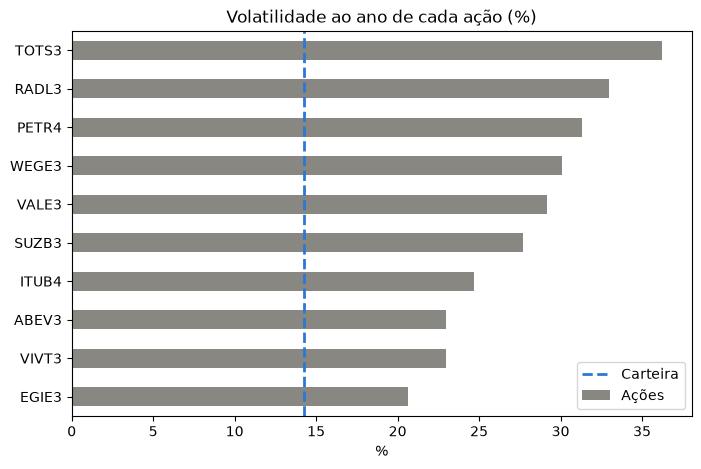

In [17]:
vol_carteira = volatilidade_anual(curvas["Carteira"]) * 100

ax = risco_acoes["Volatilidade ao ano (%)"].sort_values().plot.barh(
    figsize=(8, 5), color="#898781", label="Ações"
)
ax.axvline(vol_carteira, color="#2a78d6", linestyle="--", linewidth=2, label="Carteira")
ax.set_title("Volatilidade ao ano de cada ação (%)")
ax.set_xlabel("%")
ax.set_ylabel("")
ax.legend()
plt.show()

**O efeito da diversificação.** Em geral, a volatilidade da carteira fica abaixo da maioria das ações, mesmo sendo feita delas. É o efeito da diversificação: as ações não sobem e caem todas ao mesmo tempo nem na mesma intensidade, e as quedas de umas são parcialmente compensadas pelas altas de outras. Esse é o tema da aula 5.

**[Preencher: quantas ações ficaram acima da linha da carteira.]**

## Parte 5 · Validação

### Bloco 21 · Bateria de testes

Uma boa prática ao escrever funções é manter uma célula de testes com respostas conhecidas, que pode ser rodada sempre que algo mudar no notebook. São quatro testes:

1. **Retorno total** de 100 → 110 → 121: deve dar 0,21.
2. **Queda máxima** de 100 → 120 → 90 → 110: deve dar −0,25.
3. **Volatilidade** de uma série que sobe exatamente 1% todo dia: deve dar zero, porque todos os retornos são iguais e não há dispersão.
4. **Queda máxima do CDI:** deve dar zero, porque o CDI nunca cai.

> **O que esperar:** `0.21`, `-0.25`, `0.0` e `0.0`. Se algum teste falhar, há um erro na função correspondente.

In [18]:
print("Retorno total de 100 → 110 → 121:", round(retorno_total(pd.Series([100, 110, 121])), 4))
print("Queda máxima de 100 → 120 → 90 → 110:", round(queda_maxima(pd.Series([100, 120, 90, 110])), 4))
print("Volatilidade de quem sobe 1% todo dia:", round(volatilidade_anual(pd.Series([100, 101, 102.01, 103.0301])), 4))
print("Queda máxima do CDI:", round(queda_maxima(curvas["CDI"]), 4))

Retorno total de 100 → 110 → 121: 0.21
Queda máxima de 100 → 120 → 90 → 110: -0.25
Volatilidade de quem sobe 1% todo dia: 0.0
Queda máxima do CDI: 0.0


### Bloco 22 · O Sharpe calculado de outro jeito

Existe mais de uma forma de calcular o Sharpe. A que usamos, com o retorno anual composto, é a mais intuitiva. As bibliotecas de finanças costumam usar outra: a média dos excessos diários sobre o CDI, dividida pelo desvio padrão desses excessos e multiplicada por $\sqrt{252}$.

Escrevemos essa segunda versão como uma nova função e comparamos as duas para a carteira e para o Ibovespa. Os números não vão ser iguais. A principal diferença está entre média simples e juros compostos: perder 10% num dia e ganhar 10% no seguinte dá média zero, mas deixa você com 1% a menos, porque $0{,}9 \times 1{,}1 = 0{,}99$. A média dos retornos diários ignora essa perda; o retorno anual composto, não. Quanto mais a curva oscila, maior o efeito: com volatilidade de 20% ao ano, ele fica em torno de 2 pontos percentuais por ano no retorno (cerca de metade da variância, $\sigma^2/2$).

Por isso, quando uma carteira rende perto do CDI, a versão diária tende a dar um Sharpe maior, e as duas podem até discordar no sinal: uma positiva e a outra negativa. Quando o retorno fica bem acima ou bem abaixo do CDI, entra em cena um segundo efeito, o da composição dos ganhos ao longo do ano, e a diferença pode ir para qualquer lado; o sinal, nesse caso, costuma ser o mesmo.

A lição vale para qualquer métrica: ao apresentar um número, diga como ele foi calculado.

> **O que esperar:** uma tabela com as duas versões do Sharpe, lado a lado, com valores diferentes.

In [19]:
def sharpe_diario(serie, cdi):
    """Versão comum nas bibliotecas: média dos excessos diários sobre o CDI, anualizada."""
    excesso = serie.pct_change().dropna() - cdi.pct_change().dropna()
    return excesso.mean() / excesso.std() * 252 ** 0.5


comparacao = pd.DataFrame(index=["Carteira", "Ibovespa"])
comparacao["Sharpe (versão da aula)"] = curvas[["Carteira", "Ibovespa"]].apply(sharpe, cdi=curvas["CDI"])
comparacao["Sharpe (média diária × √252)"] = curvas[["Carteira", "Ibovespa"]].apply(sharpe_diario, cdi=curvas["CDI"])
comparacao.round(2)

,Sharpe (versão da aula),Sharpe (média diária × √252)
Carteira,0.04,0.11
Ibovespa,-0.12,-0.02


**As duas versões.** **[Preencher: as duas versões concordam no sinal e na ordem entre carteira e Ibovespa? Se discordarem, ligar a diferença ao efeito dos juros compostos explicado acima.]**

## Parte 6 · Interpretação

### Bloco 23 · O que os números dizem

**[Texto a completar com os resultados reais.]**

Entre 2021 e 2026, a carteira teve volatilidade de **[x]%** ao ano, contra **[x]%** do Ibovespa e **[x]%** do CDI. A pior queda da carteira foi de **[x]%**, do pico de **[data]** ao fundo de **[data]**; a do Ibovespa foi de **[x]%**. O Sharpe da carteira foi de **[x]**, **[positivo: ela rendeu acima do CDI por unidade de risco / negativo: ela correu risco e ainda assim rendeu menos que o CDI]**.

Perguntas que orientam a interpretação:

1. **O risco foi recompensado?** A carteira entregou mais retorno por ter corrido mais risco, ou correu risco sem recompensa?
2. **Você aguentaria a queda máxima?** Transforme a queda em reais: quanto o saldo encolheu entre o pico e o fundo?
3. **Mais risco trouxe mais retorno?** Na tabela do bloco 19, as ações mais voláteis foram as que mais renderam? Em um período curto, nem sempre: risco maior significa resultados mais espalhados, para cima e para baixo.
4. **A diversificação apareceu?** A carteira oscilou menos que a maioria das ações que a compõem?

## Parte 7 · Limitações

### Bloco 24 · O que esta análise não mostra

- **A volatilidade trata altas e quedas da mesma forma.** Um dia de +5% conta como risco tanto quanto um dia de −5%. O índice de Sortino, do exercício 2, considera só as quedas.
- **A regra da raiz de 252 é uma aproximação.** Ela supõe que o retorno de um dia não influencia o do dia seguinte, o que nem sempre é verdade.
- **A queda máxima depende do período.** Quanto mais longo o histórico, mais chances de aparecer uma queda maior. Ampliar a janela nunca diminui a pior queda observada.
- **Sharpe negativo é difícil de comparar.** Entre duas carteiras que perderam para o CDI, a de Sharpe "menos negativo" não é necessariamente a melhor: com o mesmo prejuízo em relação ao CDI, a mais volátil fica com o Sharpe mais perto de zero.
- **Risco medido no passado.** O risco futuro pode ser maior ou menor.
- **O CDI não é totalmente livre de risco.** Aplicações em renda fixa também têm riscos, como o de calote do emissor e o de perder para a inflação. Ele é uma régua prática, não perfeita.

## Parte 8 · Exercícios

### Bloco 25 · Para praticar

1. **Quando a carteira se recuperou?** Encontre a primeira data, depois do fundo, em que a carteira voltou ao valor do pico. Dica: guarde `curvas["Carteira"].loc[data_fundo:]` numa variável e filtre os dias em que o valor é maior ou igual a `curvas["Carteira"].loc[data_pico]`. Se o resultado vier vazio, a carteira ainda não se recuperou.
2. **Índice de Sortino.** Escreva uma função `volatilidade_queda`, igual à `volatilidade_anual`, mas usando só os retornos diários negativos (filtre com `retornos_diarios[retornos_diarios < 0]`). Depois, escreva uma função `sortino`, igual à `sharpe`, mas dividindo pela nova volatilidade.
3. **Um ano de cada vez.** Calcule o retorno da carteira em 2022 com `retorno_total(curvas["Carteira"].loc["2022"])`. Repita para os outros anos. Na próxima aula, o laço `for` vai automatizar essa repetição.
4. **O Sharpe de cada ação.** Calcule `precos.apply(sharpe, cdi=curvas["CDI"])`. Qual ação teve o melhor retorno por unidade de risco? É a mesma que teve o maior retorno?

## Resumo

### Bloco 26 · O que aprendemos

**Em finanças:**

- Risco é a incerteza do caminho, e não só o resultado final.
- A volatilidade mede o quanto os retornos oscilam; para anualizá-la, multiplica-se pela raiz de 252.
- A queda máxima mede a pior perda do pico ao fundo.
- O Sharpe mede o retorno acima do CDI por unidade de volatilidade; negativo significa que o investimento perdeu para o CDI.
- Uma carteira costuma oscilar menos que a maioria das ações que a compõem.

**Em Python:**

- Funções são criadas com `def`, recebem parâmetros, devolvem resultados com `return` e são descritas pela docstring.
- Toda função nova deve ser testada com um exemplo de resposta conhecida.
- Funções podem chamar outras funções.
- O `apply` aplica uma função a cada coluna de uma tabela, e parâmetros extras são passados pelo nome.
- `pct_change`, `std`, `cummax`, `idxmin` e `idxmax` resolvem em uma linha contas que levariam várias.

## Gancho para a aula 3

### Bloco 27 · Próxima aula

Até aqui, colocamos R\\$ 2.000 de uma vez, no primeiro dia. Mas quase ninguém começa assim: o mais comum é guardar um pouco por mês. Investir aos poucos muda o resultado? Muda a experiência de atravessar as quedas?

Na próxima aula, vamos simular R\\$ 200 por mês, durante 60 meses, na carteira, no Ibovespa e no CDI. E o Python ganha uma ferramenta nova: o laço `for`, que repete uma tarefa para cada mês.

## Glossário da aula

| Termo | Significado |
|---|---|
| Retorno diário | Variação percentual de um dia para o outro |
| Volatilidade | Dispersão dos retornos; medida pelo desvio padrão |
| Desvio padrão | Distância típica entre cada valor e a média |
| Anualização | Conversão de uma medida diária para a escala de um ano |
| Drawdown | Quanto o valor está abaixo do maior valor já atingido |
| Queda máxima | O pior drawdown do período |
| Índice de Sharpe | Retorno acima da taxa livre de risco por unidade de volatilidade |
| Taxa livre de risco | Rendimento de referência sem risco de oscilação (aqui, o CDI) |
| Histograma | Gráfico que conta quantos valores caem em cada faixa |
| Função | Bloco de código com nome, que recebe valores e devolve um resultado |
| Parâmetro | Nome do valor que a função recebe |
| Docstring | Texto que descreve o que a função faz |
| `apply` | Método do pandas que aplica uma função a cada coluna |

---

*Python Finance Lab · Conteúdo exclusivamente educacional. Não constitui recomendação de investimento.*